# Split flights into segments across data gaps
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

GAP_THRESH = pd.Timedelta(2, 'hours') # if the time step is larger than this threshold, the flight
                                      # is split into segments. I picked this low value of two hours 
                                      # to be conservative: as it is, 4.7% of data get deleted for a 
                                      # minimum segment length of 2 days. If I use a value of six
                                      # hours, that percentage is only reduced to 2.7.
MIN_SEG_LEN = pd.Timedelta(2, 'days') # the minimum segment length to be used in the analysis

In [2]:
# Load in the data
flights = pd.read_feather('Concordiasi_with_ERA5_2_takeoffs_landings.feather')
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,8.44,-9.58,61.573,192.615719,0.000580,7.54
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,8.36,-9.75,61.616,192.613123,0.000580,7.70
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,8.37,-9.82,61.715,192.607186,0.000579,7.83
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,8.40,-9.79,61.751,192.605042,0.000579,7.97
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,8.43,-9.68,61.691,192.608620,0.000579,8.11
...,...,...,...,...,...,...,...,...,...,...,...
2525765,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,10.33,6.50,66.584,207.932783,0.000660,11.60
2525766,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,10.30,6.47,66.571,207.936609,0.000660,11.62
2525767,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,10.28,6.44,66.583,207.933077,0.000660,11.63
2525768,19,2010-11-23 09:58:00,-76.324539,-20.535913,17363.8,10.27,6.41,66.555,207.941321,0.000660,11.65


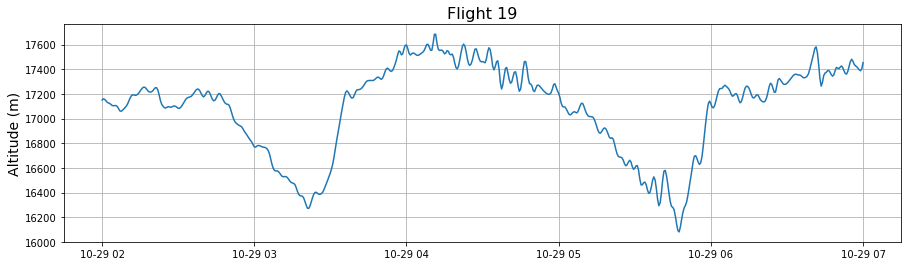

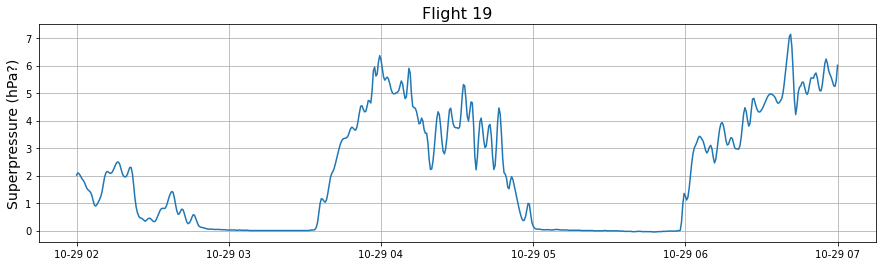

In [3]:
# Look for depressurizations

# Select a flight and zoom in on a specified time interval
flight_ids = flights.flight_id.unique()
flight_ind = 18

flight = flights[flights.flight_id == flight_ids[flight_ind]]
#time_start = flight.time.iloc[0]
#time_stop = flight.time.iloc[-1]
time_start = pd.Timestamp('2010-10-29 02:00:00.00')
time_stop = pd.Timestamp('2010-10-29 07:00:00.00')
flight = flight[flight.time >= time_start]
flight = flight[flight.time <= time_stop]


plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.altitude)
plt.grid()
plt.title(f'Flight {flight_ids[flight_ind]}', fontsize=16)
plt.ylabel('Altitude (m)', fontsize=14);

plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.superpressure)
plt.grid()
plt.title(f'Flight {flight_ids[flight_ind]}', fontsize=16)
plt.ylabel('Superpressure (hPa?)', fontsize=14);

In [3]:
# Mark depressurizations in the data
flights['depressurization'] = 0


# Flight 19
print('Flight 19 number of data points in depressurization:')
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == '19') & 
            (flights.time >= pd.Timestamp('2010-10-29 02:45:00.00')) &
            (flights.time <= pd.Timestamp('2010-10-29 03:45:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
flights.loc[(flights.flight_id == '19') & 
            (flights.time >= pd.Timestamp('2010-10-29 04:45:00.00')) &
            (flights.time <= pd.Timestamp('2010-10-29 06:00:00.00')), 'depressurization'] = 1
print(flights[flights.depressurization == 1].shape[0] - temp)
temp = flights[flights.depressurization == 1].shape[0]
print()

Flight 19 number of data points in depressurization:
121
151



In [4]:
# Delete NaN data (NaNs are indicative of already-deleted depressurizations)
# Delete time steps where there are NaNs in either the altitude, u, v, or pressure data
print('Number of altitude NaNs:', np.isnan(flights.altitude).sum())
print('Number of zonal wind NaNs:', np.isnan(flights.u).sum())
print('Number of meridional wind NaNs:', np.isnan(flights.v).sum())
print('Number of pressure NaNs:', np.isnan(flights.pressure).sum())
flights['temp_sum'] = flights.altitude + flights.u + flights.v + flights.pressure
print('Number of combined NaNs:', np.isnan(flights.temp_sum).sum())
flights = flights[np.isnan(flights.temp_sum) == False]
flights = flights.drop(columns = 'temp_sum')

# Delete marked depressurizations
flights = flights[flights.depressurization == 0]
flights = flights.drop(columns = 'depressurization')

Number of altitude NaNs: 0
Number of zonal wind NaNs: 379
Number of meridional wind NaNs: 379
Number of pressure NaNs: 0
Number of combined NaNs: 379


In [5]:
# Split into segments
def segments_from_gaps(flight):
    
    # Create a counter so that the segment ID is incremented across the flights, creating unique segment IDs
    if "counter" not in segments_from_gaps.__dict__:
        segments_from_gaps.counter = 0
        
    # Identify the time steps that are larger than GAP_THRESH
    flight['segment_id'] = (flight.time.diff() > GAP_THRESH).astype(int).cumsum()
    n_segments = flight.segment_id.max() + 1 # the segments start at zero
        
    # Apply the counter and increment it
    flight.segment_id = flight.segment_id + segments_from_gaps.counter
    segments_from_gaps.counter = segments_from_gaps.counter + n_segments
    
    return flight

# Split flights into segments when the data gap is too big
print('Splitting the flights into segments')
flights = flights.groupby('flight_id').apply(segments_from_gaps).reset_index(drop=True)
print(f'Number of segments: {flights.segment_id.nunique()}')
print()

# Delete segments that are too short
print('Calculating segment length')
n_data_before = flights.shape[0]
num_before = flights.segment_id.nunique()
segment_length = flights.groupby('segment_id').apply(lambda f: f.time.iloc[-1] - f.time.iloc[0])
segments_tooshort = segment_length[segment_length < MIN_SEG_LEN]
flights = flights[~flights.segment_id.isin(segments_tooshort.index)].reset_index(drop=True)
print(f'Removed {num_before-flights.segment_id.nunique()}/{num_before} segments that are too short')
print(f'Deleted {100*(n_data_before - flights.shape[0])/n_data_before} percent of the data')
print()

Splitting the flights into segments
Number of segments: 168

Calculating segment length
Removed 60/168 segments that are too short
Deleted 5.784123441311083 percent of the data



In [6]:
# Save the data
flights.to_feather('Concordiasi_with_ERA5_3_data_gaps.feather') 
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure,segment_id
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,8.44,-9.58,61.573,192.615719,0.000580,7.54,0
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,8.36,-9.75,61.616,192.613123,0.000580,7.70,0
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,8.37,-9.82,61.715,192.607186,0.000579,7.83,0
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,8.40,-9.79,61.751,192.605042,0.000579,7.97,0
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,8.43,-9.68,61.691,192.608620,0.000579,8.11,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2379058,19,2010-11-23 09:56:00,-76.331482,-20.582638,17357.0,10.34,6.53,66.633,207.918384,0.000660,11.57,167
2379059,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,10.33,6.50,66.584,207.932783,0.000660,11.60,167
2379060,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,10.30,6.47,66.571,207.936609,0.000660,11.62,167
2379061,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,10.28,6.44,66.583,207.933077,0.000660,11.63,167
